# **Insurance Claims – Exploratory Data Analysis (EDA)**
# Project Overview
This project focuses on performing Exploratory Data Analysis (EDA) on an Insurance Claims dataset.
# Objectives:
Understand the dataset.
Identify and handle missing values.
Remove duplicate records.
Clean inconsistent categorical data.
Detect outliers.
Visualize patterns and relationships.
- Generate meaningful insights from the data.

### Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("/content/insurance_claims_regression.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fraud_flag             227 non-null    float64
 1   days_until_settlement  237 non-null    float64
 2   claim_amount_k         237 non-null    float64
 3   claim_amount_k.1       237 non-null    float64
 4   num_previous_claims    237 non-null    float64
 5   claim_amount_k.2       237 non-null    float64
 6   claim_amount_k.3       237 non-null    float64
 7   policy_type            232 non-null    object 
 8   policy_holder_age      236 non-null    float64
 9   claim_id               236 non-null    object 
dtypes: float64(8), object(2)
memory usage: 20.4+ KB


In [2]:
df

,fraud_flag,days_until_settlement,claim_amount_k,claim_amount_k.1,num_previous_claims,claim_amount_k.2,claim_amount_k.3,policy_type,policy_holder_age,claim_id
0,0.0,76.0,NaN,NaN,2.0,NaN,NaN,Auto,69.0,C110000
1,NaN,118.0,103.70,103.70,0.0,103.70,103.70,ealth,76.0,C110001
2,0.0,24.0,147.67,147.67,0.0,147.67,147.67,Home,21.0,C110002
3,0.0,80.0,175.88,175.88,2.0,175.88,175.88,Auto,57.0,C110003
4,0.0,8.0,158.71,158.71,1.0,158.71,158.71,NaN,24.0,NaN
...,...,...,...,...,...,...,...,...,...,...
255,NaN,122.0,20.97,20.97,0.0,20.97,20.97,NaN,43.0,C110019
256,NaN,151.0,158.98,158.98,NaN,158.98,158.98,Life,50.0,C110072
257,0.0,34.0,41.83,41.83,2.0,41.83,41.83,HOME,81.0,C110232
258,0.0,36.0,119.72,119.72,4.0,119.72,119.72,Life,59.0,C110163


## **Exploratory Data Analysis Preprocessing**

## Drop Duplicates

In [44]:
df.drop_duplicates()

,fraud_flag,days_until_settlement,claim_amount_k,claim_amount_k.1,num_previous_claims,claim_amount_k.2,claim_amount_k.3,policy_type,policy_holder_age,claim_id
0,0.000000,76.0,93.46,95.701814,2.0,93.46,95.701814,Auto,69.0,C110000
1,0.026432,118.0,103.70,103.700000,0.0,103.70,103.700000,Health,76.0,C110001
2,0.000000,24.0,147.67,147.670000,0.0,147.67,147.670000,Home,21.0,C110002
3,0.000000,80.0,175.88,175.880000,2.0,175.88,175.880000,Auto,57.0,C110003
4,0.000000,8.0,158.71,158.710000,1.0,158.71,158.710000,Home,24.0,C110002
...,...,...,...,...,...,...,...,...,...,...
247,0.000000,177.0,11.82,11.820000,0.0,11.82,11.820000,Auto,47.0,C110247
248,0.000000,27.0,183.40,183.400000,0.0,183.40,183.400000,Home,79.0,C110002
249,0.000000,27.0,66.43,66.430000,4.0,66.43,66.430000,Life,79.0,C110249
251,0.026432,58.0,10.96,10.960000,0.0,10.96,10.960000,Home,82.0,C110103


In [45]:
df.isnull().sum()

,0
fraud_flag,0
days_until_settlement,0
claim_amount_k,0
claim_amount_k.1,0
num_previous_claims,0
claim_amount_k.2,0
claim_amount_k.3,0
policy_type,0
policy_holder_age,0
claim_id,0


In [46]:
df.replace(["None",'none','NA','N/A',''],np.nan, inplace=True)

## Handling MIssing Values

In [47]:
df["fraud_flag"]=df["fraud_flag"].fillna(df["fraud_flag"].mean())

In [48]:
df["claim_amount_k"]=df["claim_amount_k"].fillna(df["claim_amount_k"].median())

In [49]:
df["claim_amount_k.1"]=df["claim_amount_k.1"].fillna(df["claim_amount_k.1"].mean())

In [50]:
df["days_until_settlement"].fillna(method="ffill", inplace=True)

/tmp/ipykernel_22696/3665340060.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["days_until_settlement"].fillna(method="ffill", inplace=True)
/tmp/ipykernel_22696/3665340060.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["days_until_settlement"].fillna(method="ffill", inplace=True)


In [51]:
df["num_previous_claims"].fillna(method='bfill', inplace=True)

/tmp/ipykernel_22696/316158928.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["num_previous_claims"].fillna(method='bfill', inplace=True)
/tmp/ipykernel_22696/316158928.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["num_previous_claims"].fillna(method='bfill', inplace=True)


In [52]:
df["claim_amount_k.2"]=df["claim_amount_k.2"].fillna(df["claim_amount_k.2"].median())

In [53]:
df["claim_amount_k.3"]=df["claim_amount_k.3"].fillna(df["claim_amount_k.3"].mean())

In [54]:

print(df["policy_type"].unique())

['Auto' 'Health' 'Home' 'Life']


In [55]:
print(df["policy_type"].value_counts())

policy_type
Home      96
Auto      63
Life      54
Health    47
Name: count, dtype: int64


In [56]:
df["policy_type"]=df["policy_type"].str.strip()
df["policy_type"]=df["policy_type"].str.lower()
df

,fraud_flag,days_until_settlement,claim_amount_k,claim_amount_k.1,num_previous_claims,claim_amount_k.2,claim_amount_k.3,policy_type,policy_holder_age,claim_id
0,0.000000,76.0,93.46,95.701814,2.0,93.46,95.701814,auto,69.0,C110000
1,0.026432,118.0,103.70,103.700000,0.0,103.70,103.700000,health,76.0,C110001
2,0.000000,24.0,147.67,147.670000,0.0,147.67,147.670000,home,21.0,C110002
3,0.000000,80.0,175.88,175.880000,2.0,175.88,175.880000,auto,57.0,C110003
4,0.000000,8.0,158.71,158.710000,1.0,158.71,158.710000,home,24.0,C110002
...,...,...,...,...,...,...,...,...,...,...
255,0.026432,122.0,20.97,20.970000,0.0,20.97,20.970000,home,43.0,C110019
256,0.026432,151.0,158.98,158.980000,2.0,158.98,158.980000,life,50.0,C110072
257,0.000000,34.0,41.83,41.830000,2.0,41.83,41.830000,home,81.0,C110232
258,0.000000,36.0,119.72,119.720000,4.0,119.72,119.720000,life,59.0,C110163


In [57]:
print(df["policy_type"].unique())

['auto' 'health' 'home' 'life']


In [58]:
df["policy_type"]=df["policy_type"].replace({
    "auto" : "Auto",
    "uto" : "Auto",
    "auo" : "Auto",
    "aut" : "Auto",
    "ato" : "Auto",
    "ealth" : "Health",
    "health" : "Health",
    "healh" : "Health",
    "heath" : "Health",
    "lif" : "Life",
    "life" : "Life",
    "lie" : "Life",
    "home" : "Home",
    "hom" : "Home",
    "hme" : "Home",
    "hoe" : "Home",
    "ome" : "Home"
})
df

,fraud_flag,days_until_settlement,claim_amount_k,claim_amount_k.1,num_previous_claims,claim_amount_k.2,claim_amount_k.3,policy_type,policy_holder_age,claim_id
0,0.000000,76.0,93.46,95.701814,2.0,93.46,95.701814,Auto,69.0,C110000
1,0.026432,118.0,103.70,103.700000,0.0,103.70,103.700000,Health,76.0,C110001
2,0.000000,24.0,147.67,147.670000,0.0,147.67,147.670000,Home,21.0,C110002
3,0.000000,80.0,175.88,175.880000,2.0,175.88,175.880000,Auto,57.0,C110003
4,0.000000,8.0,158.71,158.710000,1.0,158.71,158.710000,Home,24.0,C110002
...,...,...,...,...,...,...,...,...,...,...
255,0.026432,122.0,20.97,20.970000,0.0,20.97,20.970000,Home,43.0,C110019
256,0.026432,151.0,158.98,158.980000,2.0,158.98,158.980000,Life,50.0,C110072
257,0.000000,34.0,41.83,41.830000,2.0,41.83,41.830000,Home,81.0,C110232
258,0.000000,36.0,119.72,119.720000,4.0,119.72,119.720000,Life,59.0,C110163


In [59]:
df["claim_id"]=df["claim_id"].fillna(df["claim_id"].mode()[0])

In [60]:
df["policy_type"]=df["policy_type"].fillna(df["policy_type"].mode()[0])

In [61]:
df["policy_holder_age"]=df["policy_holder_age"].fillna(df["policy_holder_age"].median())

In [62]:
df

,fraud_flag,days_until_settlement,claim_amount_k,claim_amount_k.1,num_previous_claims,claim_amount_k.2,claim_amount_k.3,policy_type,policy_holder_age,claim_id
0,0.000000,76.0,93.46,95.701814,2.0,93.46,95.701814,Auto,69.0,C110000
1,0.026432,118.0,103.70,103.700000,0.0,103.70,103.700000,Health,76.0,C110001
2,0.000000,24.0,147.67,147.670000,0.0,147.67,147.670000,Home,21.0,C110002
3,0.000000,80.0,175.88,175.880000,2.0,175.88,175.880000,Auto,57.0,C110003
4,0.000000,8.0,158.71,158.710000,1.0,158.71,158.710000,Home,24.0,C110002
...,...,...,...,...,...,...,...,...,...,...
255,0.026432,122.0,20.97,20.970000,0.0,20.97,20.970000,Home,43.0,C110019
256,0.026432,151.0,158.98,158.980000,2.0,158.98,158.980000,Life,50.0,C110072
257,0.000000,34.0,41.83,41.830000,2.0,41.83,41.830000,Home,81.0,C110232
258,0.000000,36.0,119.72,119.720000,4.0,119.72,119.720000,Life,59.0,C110163


In [63]:
df.isnull().sum()

,0
fraud_flag,0
days_until_settlement,0
claim_amount_k,0
claim_amount_k.1,0
num_previous_claims,0
claim_amount_k.2,0
claim_amount_k.3,0
policy_type,0
policy_holder_age,0
claim_id,0


## **Exploratory Data Analysis and Visualization**

## Count Plot

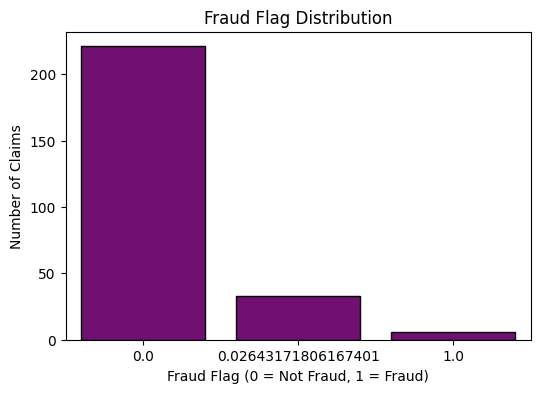

In [79]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='fraud_flag',color="purple",edgecolor="black")
plt.title('Fraud Flag Distribution')
plt.xlabel('Fraud Flag (0 = Not Fraud, 1 = Fraud)')
plt.ylabel('Number of Claims')
plt.show()

## Histogram in plt

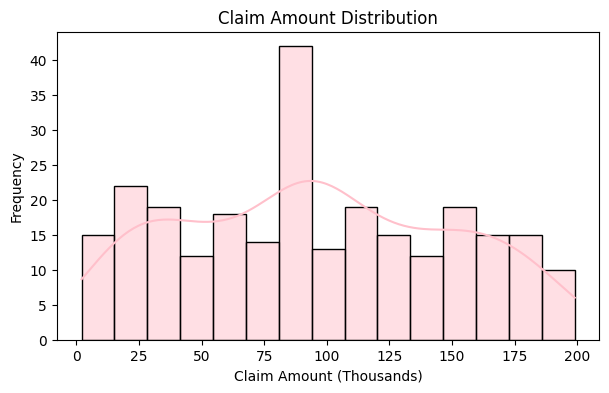

In [78]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='claim_amount_k', bins=15, kde=True,color="pink",edgecolor="black")
plt.title('Claim Amount Distribution')
plt.xlabel('Claim Amount (Thousands)')
plt.ylabel('Frequency')

plt.show()

## Scatterplot

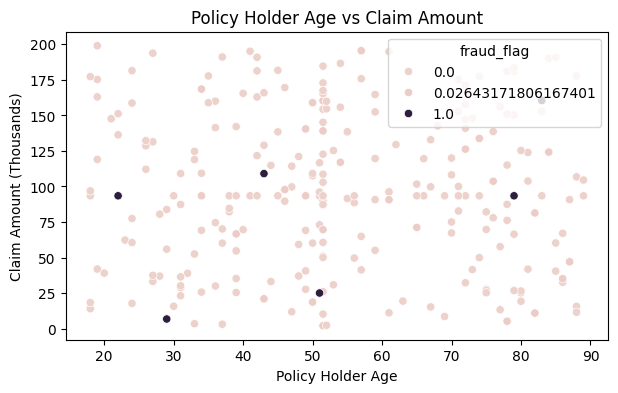

In [66]:
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df,
    x='policy_holder_age',
    y='claim_amount_k',
    hue='fraud_flag'
)
plt.title('Policy Holder Age vs Claim Amount')
plt.xlabel('Policy Holder Age')
plt.ylabel('Claim Amount (Thousands)')
plt.show()

## Heat Map

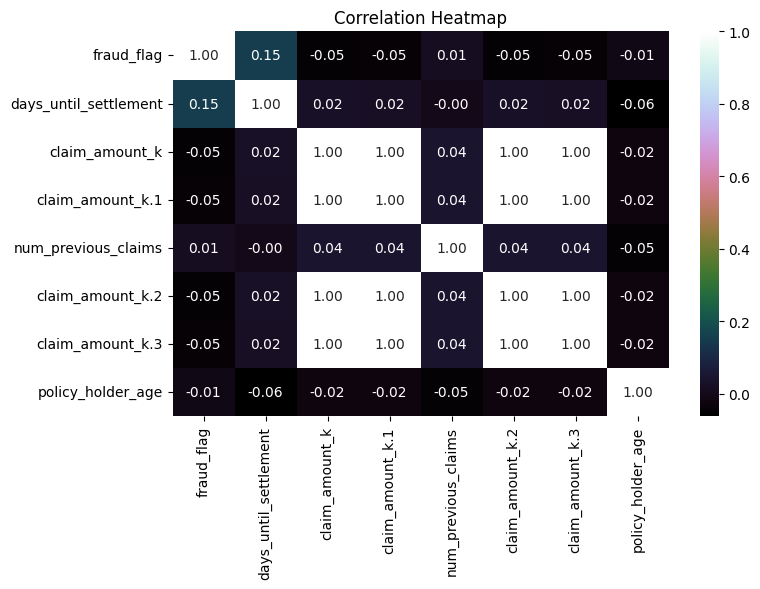

In [77]:
plt.figure(figsize=(8, 5))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='cubehelix', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## Boxplot

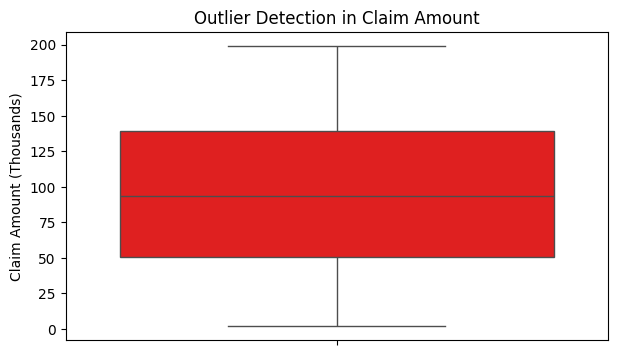

In [72]:
plt.figure(figsize=(7, 4))
sns.boxplot(y=df['claim_amount_k'],color="Red")
plt.title('Outlier Detection in Claim Amount')
plt.ylabel('Claim Amount (Thousands)')
plt.show()

## Quantile

In [69]:
Q1 = df['claim_amount_k'].quantile(0.25)
Q3 = df['claim_amount_k'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['claim_amount_k'] < lower) | (df['claim_amount_k'] > upper)]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Number of Outliers:", len(outliers))

Q1: 50.675
Q3: 139.475
IQR: 88.8
Lower Limit: -82.52499999999999
Upper Limit: 272.67499999999995
Number of Outliers: 0


In [70]:
num_cols = [
    'days_until_settlement',
    'claim_amount_k',
    'num_previous_claims',
    'policy_holder_age'
]
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]
    print(col, ":", len(outliers), "outliers")

days_until_settlement : 0 outliers
claim_amount_k : 0 outliers
num_previous_claims : 0 outliers
policy_holder_age : 0 outliers


In [71]:
df.to_csv('insurance_claims_cleaned.csv', index=False)
print("Cleaned dataset saved successfully!")
print("\nFinal Dataset Shape:")
print(df.shape)
print("\nMissing Values:")
print(df.isnull().sum().sum())

Cleaned dataset saved successfully!

Final Dataset Shape:
(260, 10)

Missing Values:
0
